# MeterTrace — Notebook 08: Interactive Customer Investigation

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 8 of 8

## Purpose
A simple, notebook-based **investigation view** for one held-out **test** customer at a time. It brings
together everything the project produced:

| Panel | What it shows | Source |
|---|---|---|
| 1. Customer summary | Label, Random Forest score, frozen threshold, flag, key features | Notebooks 03, 06 |
| 2. Consumption history | Daily readings, missing days, zero days, spikes, drops, long near-zero periods | Notebook 02 (not imputed) |
| 3. Model explanation | Which features pushed this customer's Random Forest score up or down (SHAP) | Notebooks 04, 07 |
| 4. All five models | Each model's saved score, threshold, flag and rank among test customers | Notebook 06 |
| 5. Unusual periods | Week-by-week autoencoder reconstruction error, with imputed weeks marked | Notebooks 02, 05 |

**Everything is read-only.** No model is trained, refitted or tuned. Notebook 06's test results and frozen
thresholds are only displayed. A flagged customer is an **investigation lead, not proof of theft**.

---

## How to demonstrate this notebook in 3–5 minutes
1. **Before the demo:** run all cells once (*Runtime → Run all* in Colab, or *Run → Run All Cells* in
   Jupyter). Loading takes well under a minute.
2. **Minute 0–1:** scroll to **Step 1 (choose a customer)**. Explain that the list contains three typical
   example customers from Notebook 07 and the Random Forest's top-10 test customers, and that any test
   customer can be entered by ID.
3. **Minute 1–2:** pick **"Correctly flagged theft"**, then run **Step 2** (*Run → Run All Below* in Jupyter,
   or *Runtime → Run cells after* in Colab). Walk through:
   - the summary (score 0.380 vs threshold 0.25),
   - the consumption plot (grey = missing days, not zero),
   - the SHAP bars.
4. **Minute 2–3:** pick **"False alarm (normal flagged)"** and run Step 2 again. Point out that the same
   features (large, variable consumption) caused a flag for a normal-labelled customer, so **human review is
   essential**.
5. **Minute 3–4:** pick **"Missed theft"** and run Step 2 again. Show the long near-zero period in 2015 and
   the autoencoder's week-by-week error. Explain that the Random Forest's features capture this pattern only
   partly.
6. **Minute 4–5:** show the **all-five-models table**. Explain that the scores are on different scales, so
   compare *flags* and *ranks*, not raw numbers. Close with the limitations.

*Why no live-updating widgets?* Our project rules forbid custom functions, and live ipywidgets need a
callback function. So the widgets only **hold your choice**, and the cells below **read it when you run
them**.

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow's low-level C++ log messages (Python errors still show)

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import tensorflow as tf
import keras
import ipywidgets as widgets
from IPython.display import display, Markdown

I0000 00:00:1793260757.874459     815 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793260757.875139     815 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793260759.126544     815 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793260759.127289     815 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

# ---- Saved settings from earlier notebooks (never recomputed) ----
preprocessing_params = json.loads((PROCESSED_DIR / "preprocessing_params.json").read_text())
features_metadata = json.loads((PROCESSED_DIR / "features_metadata.json").read_text())
FEATURE_COLUMNS = features_metadata["feature_columns"]
LABEL_COLUMN = features_metadata["label_column"]
FEATURE_CONSTANTS = features_metadata["constants"]          # spike/drop rule from Notebook 03
LOG_TRAIN_MEAN = preprocessing_params["log_train_mean"]
LOG_TRAIN_STD = preprocessing_params["log_train_std"]
N_WEEKS = preprocessing_params["n_weeks"]
WEEK_START_DATES = pd.date_range(preprocessing_params["first_date"], periods=N_WEEKS, freq="7D")

MODEL_NAMES = ["Logistic Regression", "Random Forest", "LSTM classifier", "Isolation Forest", "Dense autoencoder"]
MAIN_MODEL = "Random Forest"

# ---- Display-only setting (a visual aid, NOT a model feature) ----
NEAR_ZERO_KWH = 0.5              # a day below 0.5 kWh counts as "near zero" in the plot
MIN_NEAR_ZERO_RUN_DAYS = 14      # shade near-zero stretches of at least 14 consecutive observed days

# ---- Default selection used when the notebook is run top to bottom ----
DEFAULT_SELECTION = "Correctly flagged theft"
DEFAULT_CUSTOMER_ID_TEXT = ""
FALLBACK_EXAMPLE = "Correctly flagged theft"   # shown if a typed ID matches no (or several) test customers

TOWARDS_THEFT_COLOR = "#eb6834"
TOWARDS_NORMAL_COLOR = "#2a78d6"
NEUTRAL_COLOR = "#52514e"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Check that every required file exists

In [3]:
required_files = [
    PROCESSED_DIR / "daily_clean.parquet", PROCESSED_DIR / "features_test.parquet", PROCESSED_DIR / "features_train.parquet",
    PROCESSED_DIR / "weekly_test.npz", MODEL_DIR / "random_forest.joblib", MODEL_DIR / "dense_autoencoder.keras",
    RESULTS_DIR / "06_test_scores.csv", RESULTS_DIR / "06_validation_thresholds.csv", RESULTS_DIR / "07_local_explanations.csv",
]
missing_files = [str(path.relative_to(PROJECT_ROOT)) for path in required_files if not path.exists()]
print("All required files found." if len(missing_files) == 0 else f"MISSING: {missing_files} -> run Notebooks 02-07 first.")

All required files found.


## 1. Load the saved results, data and models (read-only)

In [4]:
test_scores = pd.read_csv(RESULTS_DIR / "06_test_scores.csv", index_col="CONS_NO")
frozen_thresholds = pd.read_csv(RESULTS_DIR / "06_validation_thresholds.csv", index_col="Model")["Threshold"]
test_features = pd.read_parquet(PROCESSED_DIR / "features_test.parquet")
training_median = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")[FEATURE_COLUMNS].median()
weekly_test = np.load(PROCESSED_DIR / "weekly_test.npz")

daily_clean = pd.read_parquet(PROCESSED_DIR / "daily_clean.parquet").loc[test_scores.index]
daily_clean.columns = pd.to_datetime(daily_clean.columns)

random_forest = joblib.load(MODEL_DIR / "random_forest.joblib")
autoencoder = keras.models.load_model(MODEL_DIR / "dense_autoencoder.keras")
tree_explainer = shap.TreeExplainer(random_forest)
THEFT_CLASS_INDEX = int(np.where(random_forest.classes_ == 1)[0][0])
RF_THRESHOLD = float(frozen_thresholds[MAIN_MODEL])

print("Test customers:", len(test_scores), "| frozen Random Forest threshold:", RF_THRESHOLD)

Test customers: 6356 | frozen Random Forest threshold: 0.25


### Alignment checks
All files must describe the same test customers in the same order. Every line must print `True`.

In [5]:
print("Features and saved scores in the same order:   ", bool((test_features.index == test_scores.index).all()))
print("Weekly sequences in the same order:            ", bool((weekly_test["customer_ids"] == test_scores.index.to_numpy()).all()))
print("Daily readings in the same order:              ", bool((daily_clean.index == test_scores.index).all()))
print("Labels identical in features, weekly and scores:",
      bool((test_features[LABEL_COLUMN] == test_scores[LABEL_COLUMN]).all() and (weekly_test["labels"] == test_scores[LABEL_COLUMN].to_numpy()).all()))
print("Saved Random Forest reproduces the saved scores:",
      np.allclose(random_forest.predict_proba(test_features[FEATURE_COLUMNS])[:, THEFT_CLASS_INDEX], test_scores[MAIN_MODEL]))

Features and saved scores in the same order:    True
Weekly sequences in the same order:             True
Daily readings in the same order:               True
Labels identical in features, weekly and scores: True
Saved Random Forest reproduces the saved scores: True


### Customers available for quick selection
- **Three example customers:** the *typical* correctly flagged, falsely flagged and missed customers chosen by
  the fixed rule in Notebook 07 (closest to their group's median score).
- **The Random Forest's 10 highest-scored test customers**, the first people an inspector would visit.
- **Any other test customer** by typing their ID (or a unique beginning of it) in the text box.

In [6]:
local_explanations_07 = pd.read_csv(RESULTS_DIR / "07_local_explanations.csv")
example_customers = local_explanations_07.drop_duplicates("group").set_index("group")["customer"]

top_ten = test_scores[MAIN_MODEL].sort_values(ascending=False, kind="stable").head(10)
top_ten_table = pd.DataFrame({
    "Customer ID": top_ten.index,
    "Random Forest score": top_ten.to_numpy(),
    "Label": np.where(test_scores.loc[top_ten.index, LABEL_COLUMN] == 1, "theft", "normal"),
})
top_ten_table.index = np.arange(1, 11)
top_ten_table.index.name = "Rank"

selection_options = list(example_customers.index)
for rank, customer_id in enumerate(top_ten.index, start=1):
    selection_options.append(f"Top {rank} by Random Forest: {customer_id[:12]}…")
selection_options.append("Enter a customer ID below")

print(example_customers.to_string())
top_ten_table

group
Correctly flagged theft         6BAED28FA2C707C0B5252E599AECE21C
False alarm (normal flagged)    7169453F4DC3F25BA23E9FFF01C3ABFB
Missed theft                    3458D6B72AFE936A28DDF7896665FF91


,Customer ID,Random Forest score,Label
Rank,,,
1,651DA18014E9C600248399AA174503EB,0.88,theft
2,3386E470AF725021F28437AF0DF1A292,0.87,theft
3,28A1DCF56B2B30F6C6849F2E36D1EC84,0.74,theft
4,516954F5FF177CE314656D727FCC66A5,0.72,theft
5,2173D854DB951A776D6D9B386D64F42D,0.72,theft
6,4105F5CFCC7533A415B71C22DFC30D6A,0.72,theft
7,EE80A18CF161599EED279E45957176D7,0.71,theft
8,BD99CD0FD19B40199A31858C6695F43B,0.71,theft
9,128731F9B671C5C5792879A402D49529,0.71,theft


## Step 1 — Choose a customer
Use the **dropdown**. To look at any other test customer, choose *"Enter a customer ID below"* and type the
ID, or just its first characters if they are unique, into the text box.

**Then run every cell under Step 2.** The widgets only *store* your choice; nothing updates until you run
those cells.

In [7]:
customer_dropdown = widgets.Dropdown(options=selection_options, value=DEFAULT_SELECTION,
                                     description="Customer:", layout=widgets.Layout(width="520px"))
customer_id_box = widgets.Text(value=DEFAULT_CUSTOMER_ID_TEXT, placeholder="e.g. 6BAED28FA2C7 (unique beginning is enough)",
                               description="Customer ID:", layout=widgets.Layout(width="520px"))
display(widgets.VBox([customer_dropdown, customer_id_box]))

## Step 2 — Run the investigation
### 2a. Read the selection

In [8]:
selected_option = customer_dropdown.value
selection_message = ""

if selected_option in example_customers.index:
    CUSTOMER_ID = example_customers[selected_option]
    selection_message = f"Example customer: **{selected_option}**"
elif selected_option.startswith("Top "):
    top_rank = int(selected_option.split(" ")[1])
    CUSTOMER_ID = top_ten.index[top_rank - 1]
    selection_message = f"Random Forest top-10 customer, rank **{top_rank}**"
else:
    typed_text = customer_id_box.value.strip().upper()
    matching_ids = test_scores.index[test_scores.index.str.startswith(typed_text)] if typed_text != "" else []
    if len(matching_ids) == 1:
        CUSTOMER_ID = matching_ids[0]
        selection_message = f"Customer typed in the text box (`{typed_text}`)"
    else:
        CUSTOMER_ID = example_customers[FALLBACK_EXAMPLE]
        selection_message = (f"⚠️ `{typed_text}` matched **{len(matching_ids)}** test customers (need exactly 1). "
                             f"Showing the example customer instead: **{FALLBACK_EXAMPLE}**")

display(Markdown(selection_message + f"  \nSelected customer ID: `{CUSTOMER_ID}`"))

Example customer: **Correctly flagged theft**  
Selected customer ID: `6BAED28FA2C707C0B5252E599AECE21C`

### 2b. Customer summary

In [9]:
customer_label = int(test_scores.loc[CUSTOMER_ID, LABEL_COLUMN])
customer_rf_score = float(test_scores.loc[CUSTOMER_ID, MAIN_MODEL])
customer_flagged = bool(test_scores.loc[CUSTOMER_ID, f"{MAIN_MODEL} flagged"])
customer_rank = int((test_scores[MAIN_MODEL] > customer_rf_score).sum()) + 1

display(Markdown(f'''
| | |
|---|---|
| **Customer ID** | `{CUSTOMER_ID}` |
| **Dataset label** | {"theft-labelled" if customer_label == 1 else "normal-labelled"} |
| **Random Forest score** | {customer_rf_score:.3f} |
| **Frozen threshold (Notebook 06)** | {RF_THRESHOLD:.3f} |
| **Decision** | {"🚩 **FLAGGED** for inspection" if customer_flagged else "not flagged"} |
| **Rank among {len(test_scores):,} test customers** | about {customer_rank:,} (1 = most suspicious; equal scores share a rank) |
| **In a contradictory-label group** | {"yes" if bool(test_scores.loc[CUSTOMER_ID, "in_contradictory_group"]) else "no"} |

> **This is an investigation lead, not proof of theft.** The score says how similar this customer's
> consumption summary is to theft-labelled customers in the training data. Only a human inspection can
> establish what actually happened.
'''))

key_features = pd.DataFrame({
    "This customer": test_features.loc[CUSTOMER_ID, FEATURE_COLUMNS],
    "Median training customer": training_median,
}).round(3)
key_features


| | |
|---|---|
| **Customer ID** | `6BAED28FA2C707C0B5252E599AECE21C` |
| **Dataset label** | theft-labelled |
| **Random Forest score** | 0.380 |
| **Frozen threshold (Notebook 06)** | 0.250 |
| **Decision** | 🚩 **FLAGGED** for inspection |
| **Rank among 6,356 test customers** | about 142 (1 = most suspicious; equal scores share a rank) |
| **In a contradictory-label group** | no |

> **This is an investigation lead, not proof of theft.** The score says how similar this customer's
> consumption summary is to theft-labelled customers in the training data. Only a human inspection can
> establish what actually happened.


,This customer,Median training customer
mean_kwh,67.903,5.662
median_kwh,63.070,4.760
std_kwh,42.542,3.257
max_kwh,227.430,22.890
zero_ratio,0.017,0.007
missing_ratio,0.709,0.109
volatility,0.207,0.238
longest_zero_run_days,5.000,2.000
spike_frequency,0.020,0.002
drop_frequency,0.040,0.013


### 2c. Daily consumption history
These are the **real daily readings** (capped in Notebook 02, **never imputed**):

| Mark | Meaning |
|---|---|
| **Grey background** | **Missing** days (no reading). Missing is **not** the same as zero |
| **Black dots on the zero line** | Days with a real reading of exactly **0 kWh** |
| **Orange ▲** | **Spikes**: ≥ 3 × the customer's average of the previous 7 days (Notebook 03 rule) |
| **Blue ▼** | **Sudden drops**: ≤ ⅓ × that average (Notebook 03 rule) |
| **Light orange background** | **Long near-zero periods**: at least 14 consecutive observed days below 0.5 kWh. This is a display aid only; the models did not use it |

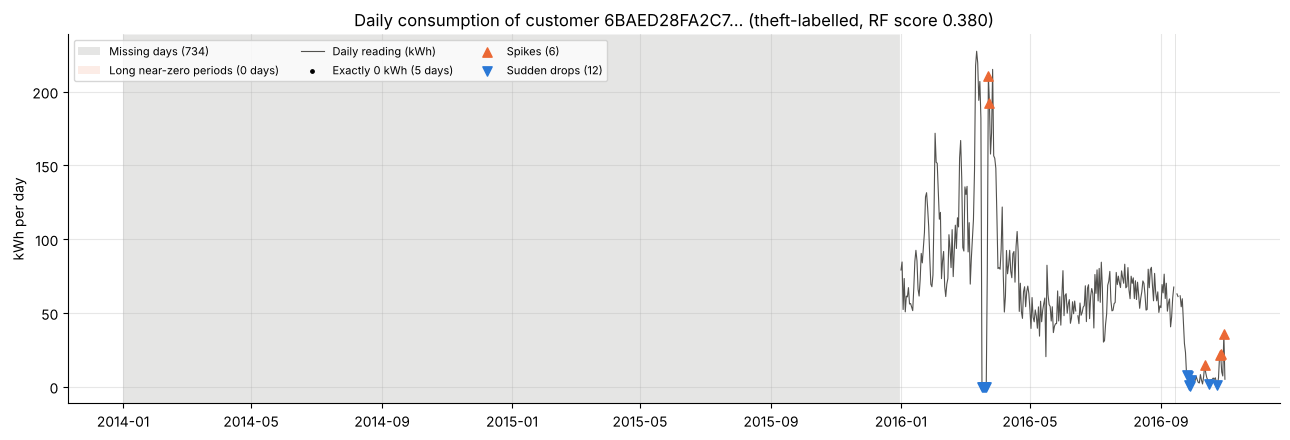

Check: plotted spikes/drops reproduce the saved Notebook 03 features -> True


In [10]:
customer_daily = daily_clean.loc[CUSTOMER_ID]
is_missing_day = customer_daily.isna()
is_zero_day = customer_daily == 0

# The rules below use exactly the days Notebook 03 used: the two artificial days are left out
artificial_days = pd.to_datetime([preprocessing_params["blanked_glitch_date"], preprocessing_params["inserted_absent_date"]])
readings_for_rules = customer_daily.drop(artificial_days)

# Spikes and drops: the same rule as Notebook 03, applied to this one customer
recent_average = readings_for_rules.rolling(FEATURE_CONSTANTS["baseline_days"], min_periods=FEATURE_CONSTANTS["min_baseline_days"]).mean().shift(1)
is_comparable = readings_for_rules.notna() & (recent_average >= FEATURE_CONSTANTS["min_baseline_kwh"])
is_spike_day = is_comparable & (readings_for_rules >= FEATURE_CONSTANTS["spike_multiplier"] * recent_average)
is_drop_day = is_comparable & (readings_for_rules <= FEATURE_CONSTANTS["drop_fraction"] * recent_average)

# Long near-zero periods: label consecutive runs, measure their length, keep runs of >= 14 days
is_near_zero_day = readings_for_rules.notna() & (readings_for_rules < NEAR_ZERO_KWH)
run_number = (is_near_zero_day != is_near_zero_day.shift()).cumsum()
run_length = is_near_zero_day.groupby(run_number).transform("size")
is_long_near_zero = (is_near_zero_day & (run_length >= MIN_NEAR_ZERO_RUN_DAYS)).reindex(customer_daily.index, fill_value=False)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(customer_daily.index, 0, 1, where=is_missing_day.to_numpy(), color=NEUTRAL_COLOR, alpha=0.15,
                transform=ax.get_xaxis_transform(), linewidth=0, label=f"Missing days ({int(is_missing_day.sum())})")
ax.fill_between(customer_daily.index, 0, 1, where=is_long_near_zero.to_numpy(), color=TOWARDS_THEFT_COLOR, alpha=0.12,
                transform=ax.get_xaxis_transform(), linewidth=0, label=f"Long near-zero periods ({int(is_long_near_zero.sum())} days)")
ax.plot(customer_daily.index, customer_daily.to_numpy(), color=NEUTRAL_COLOR, linewidth=0.8, label="Daily reading (kWh)")
ax.scatter(customer_daily.index[is_zero_day], np.zeros(int(is_zero_day.sum())), color="black", s=6,
           label=f"Exactly 0 kWh ({int(is_zero_day.sum())} days)", zorder=3)
ax.scatter(readings_for_rules.index[is_spike_day], readings_for_rules[is_spike_day], marker="^", color=TOWARDS_THEFT_COLOR, s=45,
           label=f"Spikes ({int(is_spike_day.sum())})", zorder=4)
ax.scatter(readings_for_rules.index[is_drop_day], readings_for_rules[is_drop_day], marker="v", color=TOWARDS_NORMAL_COLOR, s=45,
           label=f"Sudden drops ({int(is_drop_day.sum())})", zorder=4)
ax.set_ylabel("kWh per day")
ax.set_title(f"Daily consumption of customer {CUSTOMER_ID[:12]}… "
             f"({'theft' if customer_label == 1 else 'normal'}-labelled, RF score {customer_rf_score:.3f})")
ax.legend(loc="upper left", fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_demo_consumption_history.png", dpi=120)
plt.show()

comparable_days = int(is_comparable.sum())
spike_share = is_spike_day.sum() / comparable_days if comparable_days > 0 else 0.0
drop_share = is_drop_day.sum() / comparable_days if comparable_days > 0 else 0.0
print("Check: plotted spikes/drops reproduce the saved Notebook 03 features ->",
      np.isclose(spike_share, test_features.loc[CUSTOMER_ID, "spike_frequency"]) and np.isclose(drop_share, test_features.loc[CUSTOMER_ID, "drop_frequency"]))

### 2d. Why did the Random Forest give this score? (SHAP, this customer only)
SHAP splits the score into one contribution per feature:
**score = base value (0.5) + sum of contributions**.

- **Orange bars push the score up**, towards the theft label.
- **Blue bars push the score down**, towards the normal label.

This explains **the model**, not the customer's behaviour, and it does **not** establish causation.
SHAP is computed for this one customer only (a fraction of a second).

Check: base value 0.500 + contributions -0.120 = 0.380 (saved score 0.380) -> True


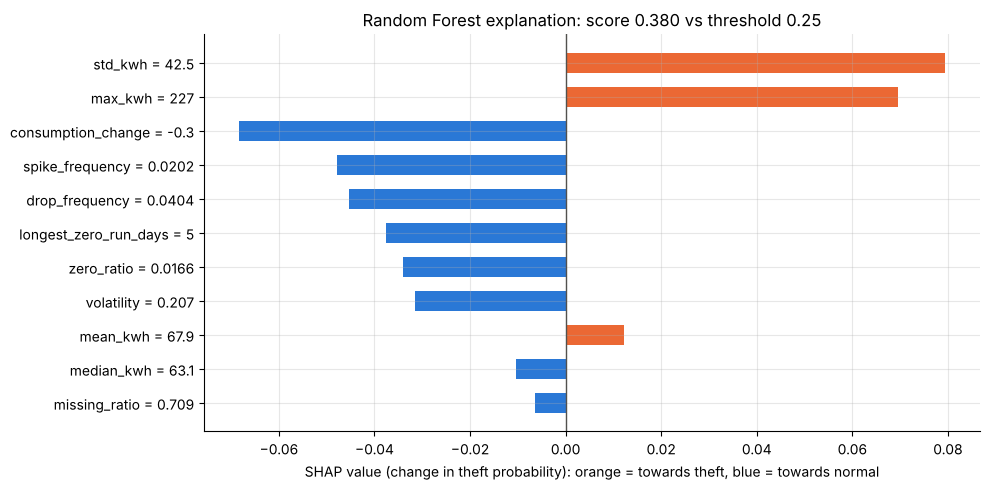

**Strongest three contributions:** `std_kwh` = 42.5 → pushes up (+0.079); `max_kwh` = 227 → pushes up (+0.070); `consumption_change` = -0.3 → pushes down (-0.068)

In [11]:
customer_feature_row = test_features.loc[[CUSTOMER_ID], FEATURE_COLUMNS]
customer_shap = np.asarray(tree_explainer.shap_values(customer_feature_row))[0, :, THEFT_CLASS_INDEX]
base_value = float(np.asarray(tree_explainer.expected_value)[THEFT_CLASS_INDEX])
contributions = pd.Series(customer_shap, index=FEATURE_COLUMNS).sort_values(key=np.abs, ascending=True)

print(f"Check: base value {base_value:.3f} + contributions {customer_shap.sum():+.3f} = {base_value + customer_shap.sum():.3f} "
      f"(saved score {customer_rf_score:.3f}) ->", np.isclose(base_value + customer_shap.sum(), customer_rf_score))

# Each bar is labelled "feature = this customer's value"
bar_labels = [f"{feature_name} = {customer_feature_row.loc[CUSTOMER_ID, feature_name]:.3g}" for feature_name in contributions.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(bar_labels, contributions.to_numpy(), height=0.6,
        color=np.where(contributions.to_numpy() > 0, TOWARDS_THEFT_COLOR, TOWARDS_NORMAL_COLOR))
ax.axvline(0, color=NEUTRAL_COLOR, linewidth=1)
ax.set_xlabel("SHAP value (change in theft probability): orange = towards theft, blue = towards normal")
ax.set_title(f"Random Forest explanation: score {customer_rf_score:.3f} vs threshold {RF_THRESHOLD:.2f}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_demo_shap_explanation.png", dpi=120)
plt.show()

top_contributions = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(3)
display(Markdown("**Strongest three contributions:** " + "; ".join(
    f"`{name}` = {customer_feature_row.loc[CUSTOMER_ID, name]:.3g} → {'pushes up' if value > 0 else 'pushes down'} ({value:+.3f})"
    for name, value in top_contributions.items())))

### 2e. What do all five models say?
The **saved** Notebook 06 scores for this customer. **The scores are on different scales**, so they cannot be
compared numerically:
- the supervised models output probabilities;
- Isolation Forest outputs an anomaly score;
- the autoencoder outputs a reconstruction error.

Two things *can* be compared across models:
- each model's **decision** against its own frozen threshold, and
- the customer's **rank**: the share of test customers that the model scored *higher* than this customer.
  Small means suspicious.

In [12]:
model_rows = []
for model_name in MODEL_NAMES:
    model_score = float(test_scores.loc[CUSTOMER_ID, model_name])
    model_rows.append({
        "Model": model_name,
        "Score type": "probability" if model_name in ["Logistic Regression", "Random Forest", "LSTM classifier"]
                      else ("anomaly score" if model_name == "Isolation Forest" else "reconstruction error"),
        "Saved score": round(model_score, 4),
        "Frozen threshold": round(float(frozen_thresholds[model_name]), 4),
        "Flagged": "yes" if bool(test_scores.loc[CUSTOMER_ID, f"{model_name} flagged"]) else "no",
        "Test customers scored higher": f"{(test_scores[model_name] > model_score).mean():.1%}",
    })
all_model_view = pd.DataFrame(model_rows).set_index("Model")
all_model_view

,Score type,Saved score,Frozen threshold,Flagged,Test customers scored higher
Model,,,,,
Logistic Regression,probability,0.9557,0.5780,yes,0.9%
Random Forest,probability,0.3800,0.2500,yes,2.2%
LSTM classifier,probability,0.7418,0.5654,yes,5.9%
Isolation Forest,anomaly score,0.6434,0.3915,yes,1.4%
Dense autoencoder,reconstruction error,0.0703,0.1009,no,21.8%


### 2f. Unusual periods: week-by-week autoencoder reconstruction error
The dense autoencoder (Notebook 05) learned to rebuild **normal** customers' 148-week patterns. Weeks it
rebuilds badly are **unusual** for this customer compared with normal usage.

> **Exploratory view only.** High-error weeks are *unusual periods*, **not confirmed theft dates**. Our labels
> are per customer and contain no dates, so no theft date can be inferred.

**Grey weeks were imputed** in Notebook 02 (no real reading that week; the `observed` mask from Notebook 02
is 0). Their values are copies or interpolations, so their errors should not be read as evidence.

Check: mean weekly error 0.0703 equals saved autoencoder score 0.0703 -> True
Imputed weeks: 104 of 148


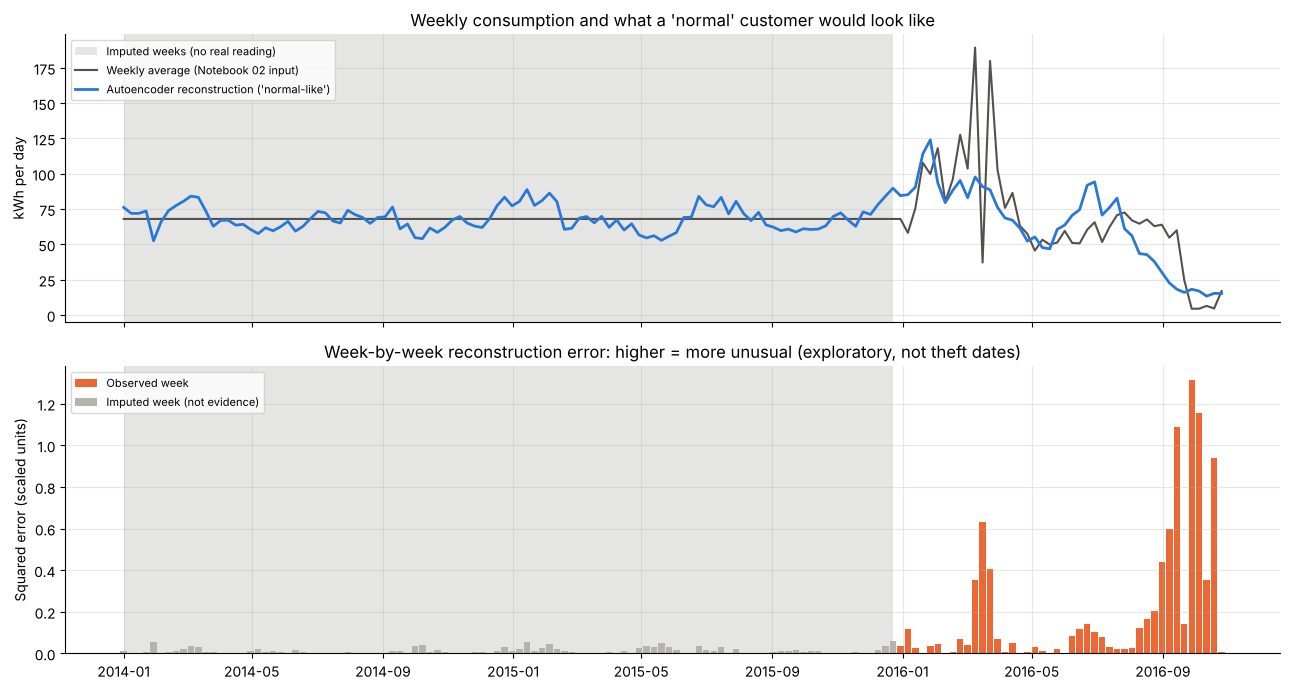

In [13]:
customer_position = int(np.where(weekly_test["customer_ids"] == CUSTOMER_ID)[0][0])
weekly_scaled = weekly_test["values"][customer_position]
weekly_observed = weekly_test["observed"][customer_position]
reconstruction_scaled = autoencoder(weekly_scaled[np.newaxis, :], training=False).numpy()[0]

weekly_squared_error = (weekly_scaled - reconstruction_scaled) ** 2
is_imputed_week = weekly_observed == 0
weekly_real_kwh = np.expm1(weekly_scaled * LOG_TRAIN_STD + LOG_TRAIN_MEAN)
weekly_rebuilt_kwh = np.expm1(reconstruction_scaled * LOG_TRAIN_STD + LOG_TRAIN_MEAN)

print(f"Check: mean weekly error {weekly_squared_error.mean():.4f} equals saved autoencoder score "
      f"{test_scores.loc[CUSTOMER_ID, 'Dense autoencoder']:.4f} ->",
      np.isclose(weekly_squared_error.mean(), test_scores.loc[CUSTOMER_ID, "Dense autoencoder"], atol=1e-5))
print(f"Imputed weeks: {int(is_imputed_week.sum())} of {N_WEEKS}")

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].fill_between(WEEK_START_DATES, 0, 1, where=is_imputed_week, color=NEUTRAL_COLOR, alpha=0.15, linewidth=0,
                     transform=axes[0].get_xaxis_transform(), label="Imputed weeks (no real reading)")
axes[1].fill_between(WEEK_START_DATES, 0, 1, where=is_imputed_week, color=NEUTRAL_COLOR, alpha=0.15, linewidth=0,
                     transform=axes[1].get_xaxis_transform())
axes[0].plot(WEEK_START_DATES, weekly_real_kwh, color=NEUTRAL_COLOR, linewidth=1.5, label="Weekly average (Notebook 02 input)")
axes[0].plot(WEEK_START_DATES, weekly_rebuilt_kwh, color=TOWARDS_NORMAL_COLOR, linewidth=2, label="Autoencoder reconstruction ('normal-like')")
axes[0].set_ylabel("kWh per day")
axes[0].set_title("Weekly consumption and what a 'normal' customer would look like")
axes[0].legend(loc="upper left", fontsize=8)

observed_error = np.where(is_imputed_week, np.nan, weekly_squared_error)
imputed_error = np.where(is_imputed_week, weekly_squared_error, np.nan)
axes[1].bar(WEEK_START_DATES, observed_error, width=6, color=TOWARDS_THEFT_COLOR, label="Observed week")
axes[1].bar(WEEK_START_DATES, imputed_error, width=6, color="#b4b3ad", label="Imputed week (not evidence)")
axes[1].set_ylabel("Squared error (scaled units)")
axes[1].set_title("Week-by-week reconstruction error: higher = more unusual (exploratory, not theft dates)")
axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_demo_autoencoder_weekly_error.png", dpi=120)
plt.show()

In [14]:
observed_weeks_table = pd.DataFrame({
    "Week starting": WEEK_START_DATES.date,
    "Weekly average (kWh/day)": weekly_real_kwh.astype(float).round(2),
    "Reconstruction (kWh/day)": weekly_rebuilt_kwh.astype(float).round(2),
    "Squared error": weekly_squared_error.astype(float).round(4),
    "Observed share of days": weekly_observed.astype(float).round(2),
})
print("Five most unusual OBSERVED weeks (exploratory):")
observed_weeks_table[~is_imputed_week].sort_values("Squared error", ascending=False).head(5)

Five most unusual OBSERVED weeks (exploratory):


,Week starting,Weekly average (kWh/day),Reconstruction (kWh/day),Squared error,Observed share of days
143,2016-09-28,4.43,18.24,1.3151,1.00
144,2016-10-05,4.48,16.93,1.1553,1.00
141,2016-09-14,59.97,18.29,1.0875,0.57
146,2016-10-19,4.59,15.32,0.9412,1.00
115,2016-03-16,37.17,90.89,0.6338,1.00


### 2g. Investigator's checklist
Before acting on any flag, a human analyst should consider:
1. **Missing readings:** are the gaps installation dates or communication faults, rather than tampering?
2. **Legitimate explanations:** a business, new appliances, a change of occupants or seasonal use can all
   create large or variable consumption.
3. **Meter faults:** spikes and near-zero periods can come from faulty meters.
4. **Label limitations:** labels are per customer, with no dates and an undocumented labelling process.
5. **Model limits:** final test Precision@100 for the Random Forest was 0.68, so roughly 1 in 3 of even the
   highest-ranked customers is normal-labelled.

**Decision:** a flag only means *"worth a closer look"*.

## Limitations of this dashboard
- **Exact zeros vs. near-zero:** the near-zero shading (below 0.5 kWh for 14+ days) is a **display aid** chosen
  for readability. The models never used it.
- **Weekly-error periods are not dates:** the weekly error plot shows *unusual* weeks compared with normal
  customers. With customer-level labels, **no theft date** can be inferred.
- **Not live-updating:** the widgets do not refresh the plots by themselves. This is deliberate, because the
  project rules forbid custom callback functions. Choose a customer, then run the Step 2 cells.
- **Test customers only:** only the 6,356 held-out test customers can be selected, because only they have
  final Notebook 06 scores.

## What We Learned
Key ideas to be able to explain in the viva:

1. **An investigation view combines evidence.** One screen brings together the label, the Random Forest
   score and its frozen threshold, the raw daily readings, the reasons for the score (SHAP), all five models'
   opinions, and the unusual weeks. A human needs all of this to decide whether an inspection is worthwhile.
2. **Missing is not zero.** The history plot shows missing days (grey) separately from real 0 kWh readings
   (black dots). Mixing them up would invent zero consumption that was never measured.
3. **Imputed values are not evidence.** Weeks filled in by Notebook 02 are drawn in grey in the autoencoder
   view and must not be read as observed behaviour.
4. **Scores live on different scales.** A Random Forest probability of 0.38 and an autoencoder error of 0.07
   cannot be compared directly. Each model's **decision against its own frozen threshold**, and the customer's
   **rank** among test customers, can be compared.
5. **Every number on screen is checked.**
   - The plotted spikes and drops reproduce the Notebook 03 features.
   - SHAP contributions add up to the saved score.
   - The weekly errors average to the saved autoencoder score.
6. **Interactivity without callbacks.** The widgets only *hold* a choice, and ordinary cells *read* it. This
   keeps the no-custom-functions rule and still allows a smooth live demo.
7. **The three example customers tell the project's story:**
   - a correctly flagged theft-labelled customer (large, variable consumption);
   - a false alarm (a large legitimate customer with the same pattern);
   - a missed case (a long near-zero period that the features captured only partly).

   Together they show what the model can do, where it fails, and why human review stays essential.
8. **A flag is a lead, not proof.** Even the best model's top 100 test customers include about 1 in 3
   normal-labelled customers.